# Level 2: The anomalous Zeeman effect (spin-orbit + Landé $g$)

**Goal.** Add electron spin and spin-orbit coupling, and reproduce the Landé $g$-factors that
explain why sodium's D lines split into 4 and 6 components rather than 3.

**Physics.**
$$H = \zeta\,\mathbf L\!\cdot\!\mathbf S + \mu_B B\,(g_l L_z + g_s S_z),\qquad
g_J = 1 + (g_s-1)\frac{j(j+1)+s(s+1)-l(l+1)}{2j(j+1)}$$
For weak fields ($\mu_B B \ll \zeta$): $\Delta E = g_J\,\mu_B B\,m_j$.

**Fixing $\zeta$ from experiment.** For one p electron, $E(j{=}3/2) - E(j{=}1/2) = \tfrac32\zeta$.
Sodium's measured 3p fine-structure splitting is $17.196\ \mathrm{cm^{-1}}$. We set $\zeta$ from that
single number. Everything after that is a prediction.

In [1]:
import sys
sys.path.insert(0, '..')          # so `import src...` works from the notebooks folder
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
from src.validation import zeta_from_fine_structure, fine_structure_splitting_cm1
from src.hamiltonians import landé_g
from src.solvers import energy_vs_field
from src.constants import MU_B_EV

zeta = zeta_from_fine_structure(17.196, l=1)
print('zeta = %.6f eV = %.4f meV' % (zeta, zeta * 1e3))
print('splitting recomputed from the matrix:', round(fine_structure_splitting_cm1(1, zeta), 6), 'cm^-1')
print('crossover field B* = zeta/mu_B = %.1f T' % (zeta / MU_B_EV))

zeta = 0.001421 eV = 1.4214 meV
splitting recomputed from the matrix: 17.196 cm^-1
crossover field B* = zeta/mu_B = 24.6 T


## Do the numerical slopes match the Landé formula?

At a small field every level moves linearly with slope $g_J m_j$ (in units of $\mu_B$).
We compute the slopes numerically and compare with the formula:

In [2]:
b = 1e-3 * zeta / MU_B_EV                                   # tiny field: mu_B B << zeta
e0 = energy_vs_field(1, [0.0], zeta)[0]
e1 = energy_vs_field(1, [b], zeta)[0]
numeric = np.sort((e1 - e0) / (MU_B_EV * b))

g12, g32 = landé_g(1, 0.5), landé_g(1, 1.5)
expected = np.sort([g12 * m for m in (-0.5, 0.5)] + [g32 * m for m in (-1.5, -0.5, 0.5, 1.5)])

print('g_J(2P1/2) = %.4f   g_J(2P3/2) = %.4f   (g_s = 2.0023)' % (g12, g32))
print('%10s %10s' % ('numeric', 'Lande'))
for n_, x in zip(numeric, expected):
    print('%10.4f %10.4f' % (n_, x))

g_J(2P1/2) = 0.6659   g_J(2P3/2) = 1.3341   (g_s = 2.0023)
   numeric      Lande
   -2.0012    -2.0012
   -0.6669    -0.6671
   -0.3331    -0.3329
    0.3328     0.3329
    0.6672     0.6671
    2.0012     2.0012


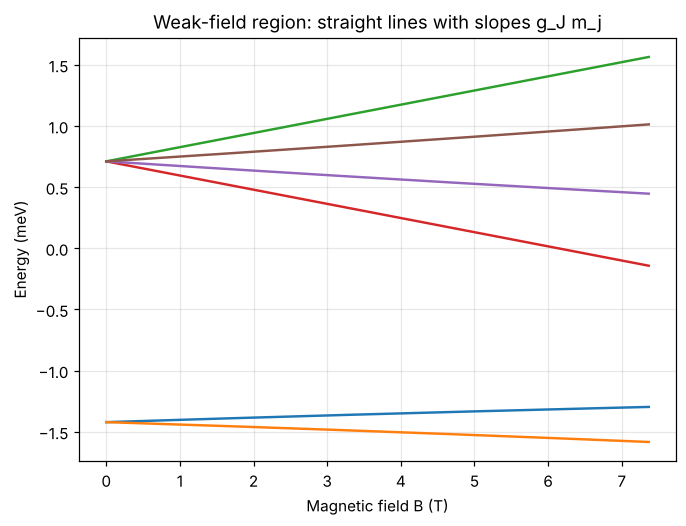

In [3]:
from src.animation import plot_energy_levels, b_scale_tesla
ax = plot_energy_levels(1, 0.3 * b_scale_tesla(zeta), zeta)
ax.set_title('Weak-field region: straight lines with slopes g_J m_j')
plt.show()

## Why 10 lines instead of 3

Compare the p to s spectrum with spin switched off (Level 1) and on (this level), at the same field:

In [4]:
from src.transitions import zeeman_lines
from src.constants import wavenumber_to_ev

gap = wavenumber_to_ev(16956.17) + zeta           # puts 2P1/2 at the measured Na D1 energy
normal = zeeman_lines(1, 0, 1.0, 0.0, 0.0, gap, g_s=0.0)
anomalous = zeeman_lines(1, 0, 1.0, zeta, 0.0, gap)
distinct = lambda d: len(np.unique(np.round(d.wavenumber_cm1.to_numpy(), 4)))
print('distinct line positions, spin off (normal Zeeman)     :', distinct(normal))
print('distinct line positions, spin-orbit on (Na D1 + D2)   :', distinct(anomalous))

distinct line positions, spin off (normal Zeeman)     : 3
distinct line positions, spin-orbit on (Na D1 + D2)   : 10


**Take-away.** Spin-orbit coupling creates two $j$ levels with *different* $g_J$ values, so the
sublevels fan out at different rates and the lines no longer coincide. Sodium D1 gives 4 lines and D2
gives 6, which is 10 in total. The numbers above reproduce the textbook $g_J = 2/3$ and $4/3$ (small
differences come from using $g_s = 2.0023$ instead of exactly 2).